In [ ]:
# Shared project paths: works when opened from the repository root or task7/notebooks.
import os
from pathlib import Path


def _find_task7_root():
    cwd = Path.cwd().resolve()
    candidates = []
    for parent in (cwd, *cwd.parents):
        candidates.extend((parent, parent / "task7"))
    for folder in candidates:
        if (folder / "results" / "task7" / "task7_split_manifest.csv").is_file():
            return folder
    raise FileNotFoundError(
        "Cannot locate task7/results/task7/task7_split_manifest.csv. "
        "Open this notebook from the extracted task7 folder or its parent repository."
    )


MODULE_ROOT = _find_task7_root()


def resolve_dataset_path(manifest_path):
    """Resolve manifest paths against the supplied dataset, not the notebook cwd."""
    path = Path(manifest_path)
    if path.is_absolute():
        if path.is_file():
            return path
        raise FileNotFoundError(path)
    # Manifest paths start with dataset_2026/<class>/<filename>.
    relative = Path(*path.parts[1:]) if path.parts and path.parts[0].lower() == "dataset_2026" else path
    explicit = os.environ.get("ME5411_DATASET_DIR", "")
    roots = ([Path(explicit)] if explicit else []) + [
        MODULE_ROOT.parent / "dataset_2026",
        MODULE_ROOT / "dataset_2026",
    ]
    for root in roots:
        candidate = root / relative
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(
        f"Missing dataset image: {manifest_path}. Place dataset_2026 next to "
        "task7/, or set ME5411_DATASET_DIR to its location."
    )

print("Task 7 directory:", MODULE_ROOT)


## Task 7 — Non-CNN: HOG + SVM

Complete experiment: raw grayscale pixels vs HOG; linear vs RBF kernels; image preprocessing and C tuning; independent test and real-chip recognition. The notebook preserves recorded outputs from the original Windows run. To **rerun training**, obtain the instructor-provided dataset and follow the README.

In [1]:
import sys
import numpy as np
import cv2
import sklearn

print("Python version:", sys.version.split()[0])
print("NumPy version:", np.__version__)
print("OpenCV version:", cv2.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("SVM environment is ready!")


Python version: 3.11.16
NumPy version: 2.4.6
OpenCV version: 5.0.0
Scikit-learn version: 1.9.1
SVM environment is ready!


## 1. Dataset split and environment

Uses a fixed 7,112-image split manifest. Only the training and validation sets are used to select the model; the test partition is reserved for final evaluation.

In [2]:
import csv
from pathlib import Path
from collections import Counter

manifest_path = MODULE_ROOT / "results/task7/task7_split_manifest.csv"

assert manifest_path.is_file(), "Cannot find split manifest!"

with open(manifest_path, "r", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    dataset_records = list(reader)

print("Total samples:", len(dataset_records))

print("Dataset splits:")
for split, count in sorted(
    Counter(r["split"] for r in dataset_records).items()
):
    print(f"{split}: {count}")

print("\nFirst sample:")
print(dataset_records[0])


Total samples: 7112
Dataset splits:
test: 1778
train: 4536
val: 798

First sample:
{'path': 'dataset_2026/0/img001-00001.png', 'label': '0', 'pixel_hash': '26666d21ed2abf8f66e06b3aa683e1ba9149c3d4b16f3376600c9fdf4025fa43', 'split': 'test'}


## 2. Raw pixel baseline

Load 32×32 grayscale pixels (1,024 features per sample), then compare raw-pixel SVM kernels.

In [3]:
import numpy as np
import cv2
from pathlib import Path

IMAGE_SIZE = 32

def load_character_image(relative_path):

    # Construct the full image path
    image_path = resolve_dataset_path(relative_path)

    # Read the image in grayscale
    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise FileNotFoundError(image_path)

    # Resize from 128x128 to 32x32
    image = cv2.resize(
        image,
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=cv2.INTER_AREA
    )

    # Normalize pixel values from 0-255 to 0-1
    image = image.astype(np.float32) / 255.0

    # Convert 32x32 matrix to 1024 features
    features = image.flatten()

    return features


Character label: 0
Feature shape: (1024,)
Minimum value: 0.0
Maximum value: 1.0


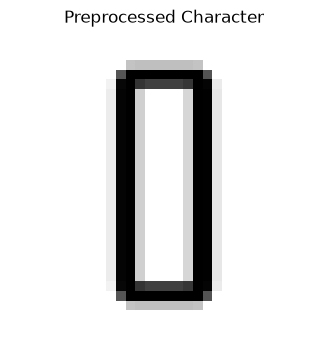

In [4]:
sample = dataset_records[0]

features = load_character_image(sample["path"])

print("Character label:", sample["label"])
print("Feature shape:", features.shape)
print("Minimum value:", features.min())
print("Maximum value:", features.max())

import matplotlib.pyplot as plt

plt.figure(figsize=(4, 4))
plt.imshow(
    features.reshape(32, 32),
    cmap="gray",
    vmin=0,
    vmax=1
)
plt.title("Preprocessed Character")
plt.axis("off")
plt.show()


In [5]:
def build_dataset(records, split_name):

    X = []
    y = []

    for record in records:

        if record["split"] != split_name:
            continue

        features = load_character_image(
            record["path"]
        )

        X.append(features)
        y.append(record["label"])

    X = np.array(X, dtype=np.float32)
    y = np.array(y)

    return X, y


X_train, y_train = build_dataset(
    dataset_records, "train"
)

X_val, y_val = build_dataset(
    dataset_records, "val"
)

print("Training data:", X_train.shape)
print("Training labels:", y_train.shape)

print("Validation data:", X_val.shape)
print("Validation labels:", y_val.shape)


Training data: (4536, 1024)
Training labels: (4536,)
Validation data: (798, 1024)
Validation labels: (798,)


In [6]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import time

# Create the SVM classifier
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

# Start training timer
start_time = time.perf_counter()

# Train the model
svm_model.fit(X_train, y_train)

training_time = time.perf_counter() - start_time

print("SVM training completed!")
print(f"Training time: {training_time:.2f} seconds")

# Predict on validation data
y_val_pred = svm_model.predict(X_val)

# Calculate validation accuracy
val_accuracy = accuracy_score(
    y_val,
    y_val_pred
)

print(f"Validation accuracy: {val_accuracy:.4f}")
print(f"Validation accuracy: {val_accuracy * 100:.2f}%")


SVM training completed!
Training time: 0.79 seconds
Validation accuracy: 0.9825
Validation accuracy: 98.25%


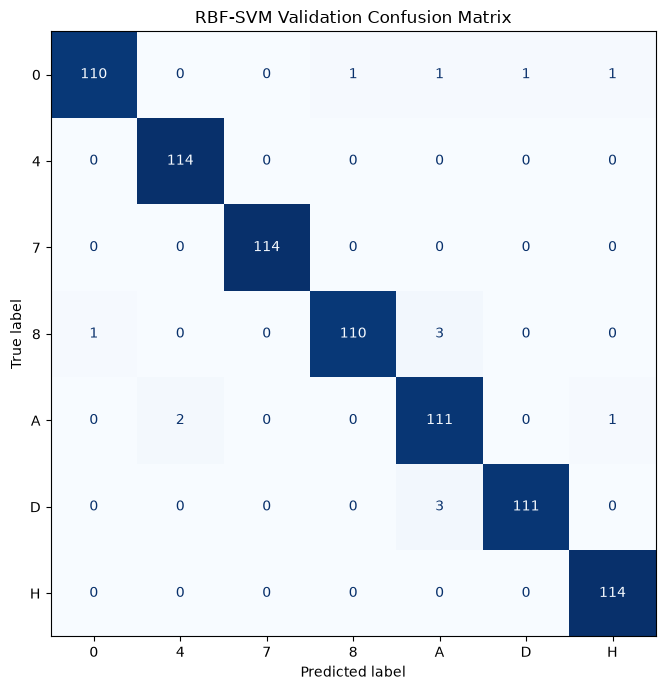

In [7]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

import matplotlib.pyplot as plt
from pathlib import Path

# Fixed character order
class_names = ["0", "4", "7", "8", "A", "D", "H"]

# Calculate confusion matrix
cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=class_names
)

# Display
fig, ax = plt.subplots(figsize=(8, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("RBF-SVM Validation Confusion Matrix")
plt.tight_layout()

# Save figure
output_dir = MODULE_ROOT / "results/task7"
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "svm_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [8]:
print("RBF-SVM Classification Report")
print("=" * 55)

print(
    classification_report(
        y_val,
        y_val_pred,
        labels=class_names,
        digits=4,
        zero_division=0
    )
)

RBF-SVM Classification Report
              precision    recall  f1-score   support

           0     0.9910    0.9649    0.9778       114
           4     0.9828    1.0000    0.9913       114
           7     1.0000    1.0000    1.0000       114
           8     0.9910    0.9649    0.9778       114
           A     0.9407    0.9737    0.9569       114
           D     0.9911    0.9737    0.9823       114
           H     0.9828    1.0000    0.9913       114

    accuracy                         0.9825       798
   macro avg     0.9827    0.9825    0.9825       798
weighted avg     0.9827    0.9825    0.9825       798



Number of incorrect predictions: 14


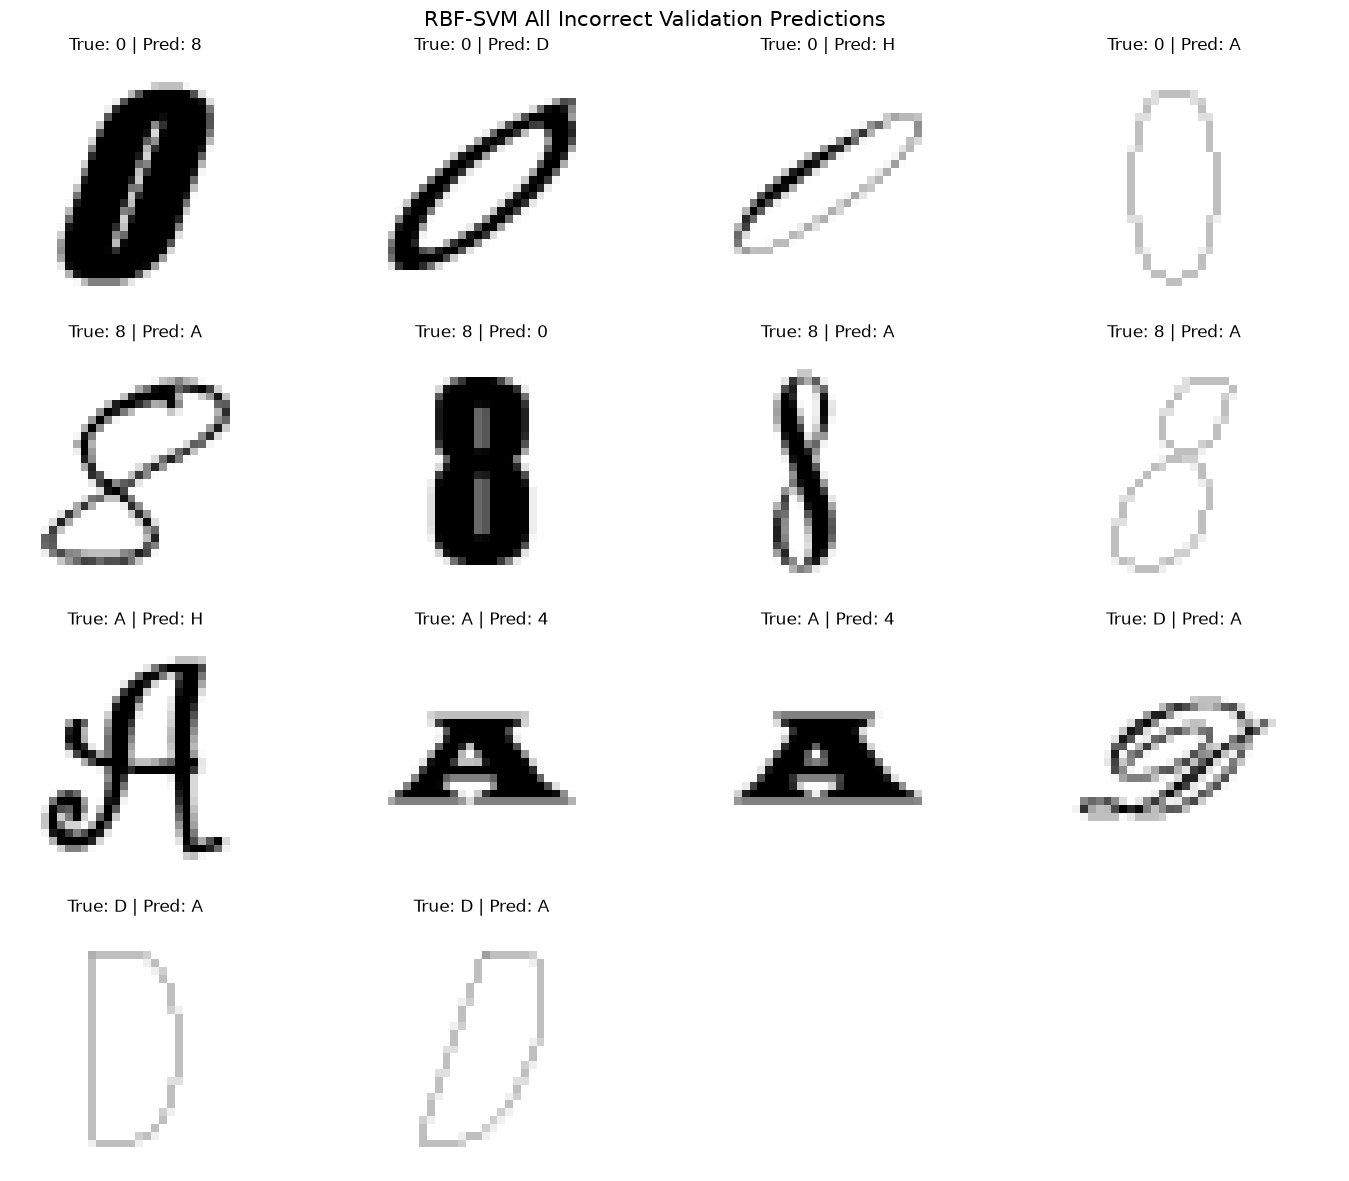

In [10]:

import numpy as np
import matplotlib.pyplot as plt
import math

wrong_indices = np.where(y_val != y_val_pred)[0]

num_errors = len(wrong_indices)

print("Number of incorrect predictions:", num_errors)

# Automatically calculate subplot layout
ncols = 4
nrows = math.ceil(num_errors / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(14, 3 * nrows)
)

axes = np.array(axes).reshape(-1)

for i, ax in enumerate(axes):

    if i < num_errors:
        idx = wrong_indices[i]

        image = X_val[idx].reshape(32, 32)

        ax.imshow(
            image,
            cmap="gray",
            vmin=0,
            vmax=1
        )

        ax.set_title(
            f"True: {y_val[idx]} | Pred: {y_val_pred[idx]}"
        )

    ax.axis("off")

plt.suptitle(
    "RBF-SVM All Incorrect Validation Predictions",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    output_dir / "svm_all_misclassified_samples.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [11]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
import time

# Create Linear SVM
svm_linear = SVC(
    kernel="linear",
    C=1.0
)

# Measure training time
start_time = time.perf_counter()

svm_linear.fit(X_train, y_train)

linear_training_time = time.perf_counter() - start_time

# Predict validation samples
y_val_pred_linear = svm_linear.predict(X_val)

# Calculate metrics
linear_accuracy = accuracy_score(
    y_val,
    y_val_pred_linear
)

linear_f1 = f1_score(
    y_val,
    y_val_pred_linear,
    average="macro"
)

print("Linear SVM training completed!")
print(f"Training time: {linear_training_time:.2f} seconds")
print(f"Validation accuracy: {linear_accuracy * 100:.2f}%")
print(f"Macro F1-score: {linear_f1:.4f}")

print(
    "Incorrect predictions:",
    sum(y_val != y_val_pred_linear)
)


Linear SVM training completed!
Training time: 0.47 seconds
Validation accuracy: 98.25%
Macro F1-score: 0.9824
Incorrect predictions: 14


In [12]:

from sklearn.metrics import accuracy_score, f1_score

models = {
    "Linear SVM": svm_linear,
    "RBF SVM": svm_model
}

comparison_results = []

for name, model in models.items():

    # Measure validation inference time
    start = time.perf_counter()
    predictions = model.predict(X_val)
    inference_time = time.perf_counter() - start

    accuracy = accuracy_score(y_val, predictions)

    macro_f1 = f1_score(
        y_val,
        predictions,
        average="macro"
    )

    errors = int(np.sum(y_val != predictions))

    ms_per_sample = (
        inference_time / len(X_val) * 1000
    )

    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Errors": errors,
        "Inference ms/sample": ms_per_sample
    })

for result in comparison_results:

    print("-" * 45)
    print("Model:", result["Model"])
    print(f"Accuracy: {result['Accuracy'] * 100:.2f}%")
    print(f"Macro F1: {result['Macro F1']:.4f}")
    print(f"Errors: {result['Errors']}")
    print(
        f"Inference: "
        f"{result['Inference ms/sample']:.4f} ms/sample"
    )


---------------------------------------------
Model: Linear SVM
Accuracy: 98.25%
Macro F1: 0.9824
Errors: 14
Inference: 0.0862 ms/sample
---------------------------------------------
Model: RBF SVM
Accuracy: 98.25%
Macro F1: 0.9825
Errors: 14
Inference: 0.3795 ms/sample


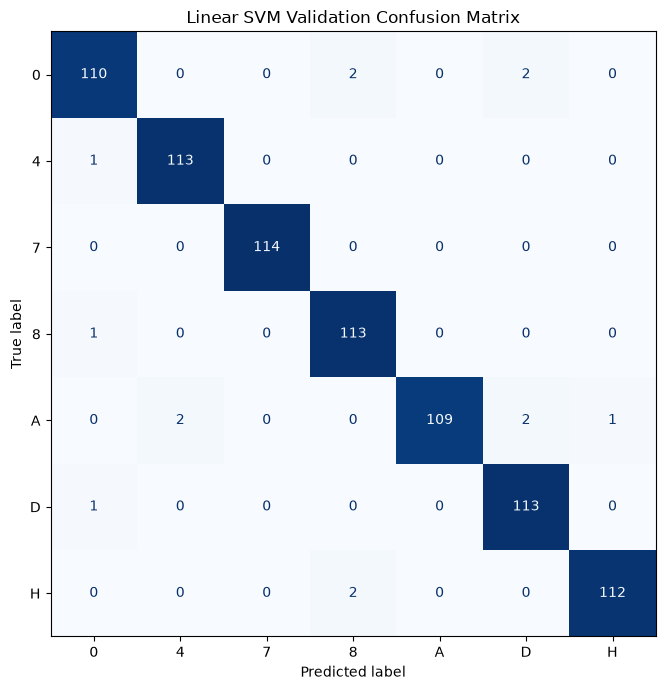

In [13]:

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
from pathlib import Path

class_names = ["0", "4", "7", "8", "A", "D", "H"]

cm_linear = confusion_matrix(
    y_val,
    y_val_pred_linear,
    labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_linear,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Linear SVM Validation Confusion Matrix")
plt.tight_layout()

output_dir = MODULE_ROOT / "results/task7"
output_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_dir / "svm_linear_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 3. HOG feature extraction and kernels

Use 324-dimensional HOG descriptors to compare linear and RBF SVMs.

In [16]:

from skimage.feature import hog
import numpy as np

# HOG feature extraction function
def extract_hog_features(X):

    hog_features = []

    for sample in X:

        # Restore the 32x32 grayscale image
        image = sample.reshape(32, 32)

        # Extract HOG features
        features = hog(
            image,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm="L2-Hys",
            feature_vector=True
        )

        hog_features.append(features)

    return np.array(hog_features, dtype=np.float32)


# Extract features from training and validation data
X_train_hog = extract_hog_features(X_train)
X_val_hog = extract_hog_features(X_val)

print("Raw training features:", X_train.shape)
print("HOG training features:", X_train_hog.shape)
print("HOG validation features:", X_val_hog.shape)
print("HOG feature dimension:", X_train_hog.shape[1])

Raw training features: (4536, 1024)
HOG training features: (4536, 324)
HOG validation features: (798, 324)
HOG feature dimension: 324


In [17]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
import time

hog_models = {}
hog_results = []

for kernel in ["linear", "rbf"]:

    model = SVC(
        kernel=kernel,
        C=1.0,
        gamma="scale"
    )

    # Training
    start = time.perf_counter()

    model.fit(X_train_hog, y_train)

    train_time = time.perf_counter() - start

    # Validation
    start = time.perf_counter()

    y_pred = model.predict(X_val_hog)

    inference_time = time.perf_counter() - start

    accuracy = accuracy_score(y_val, y_pred)

    macro_f1 = f1_score(
        y_val, y_pred, average="macro"
    )

    errors = int(np.sum(y_val != y_pred))

    ms_per_sample = (
        inference_time / len(y_val) * 1000
    )

    hog_models[kernel] = model

    hog_results.append({
        "Model": f"HOG + {kernel.upper()} SVM",
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Errors": errors,
        "Training Time": train_time,
        "Inference ms/sample": ms_per_sample
    })

    print("-" * 45)
    print(f"HOG + {kernel.upper()} SVM")
    print(f"Training time: {train_time:.3f} s")
    print(f"Accuracy: {accuracy * 100:.2f}%")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Errors: {errors}")
    print(f"Inference: {ms_per_sample:.4f} ms/sample")


---------------------------------------------
HOG + LINEAR SVM
Training time: 0.139 s
Accuracy: 99.25%
Macro F1: 0.9925
Errors: 6
Inference: 0.0204 ms/sample
---------------------------------------------
HOG + RBF SVM
Training time: 0.199 s
Accuracy: 99.00%
Macro F1: 0.9900
Errors: 8
Inference: 0.2361 ms/sample


In [18]:

print("=" * 75)
print("SVM Feature and Kernel Comparison")
print("=" * 75)

for result in comparison_results:
    print(
        f"Raw Pixels + {result['Model']:12s} | "
        f"Accuracy: {result['Accuracy']*100:.2f}% | "
        f"Macro F1: {result['Macro F1']:.4f} | "
        f"Errors: {result['Errors']}"
    )

for result in hog_results:
    print(
        f"{result['Model']:25s} | "
        f"Accuracy: {result['Accuracy']*100:.2f}% | "
        f"Macro F1: {result['Macro F1']:.4f} | "
        f"Errors: {result['Errors']}"
    )


SVM Feature and Kernel Comparison
Raw Pixels + Linear SVM   | Accuracy: 98.25% | Macro F1: 0.9824 | Errors: 14
Raw Pixels + RBF SVM      | Accuracy: 98.25% | Macro F1: 0.9825 | Errors: 14
HOG + LINEAR SVM          | Accuracy: 99.25% | Macro F1: 0.9925 | Errors: 6
HOG + RBF SVM             | Accuracy: 99.00% | Macro F1: 0.9900 | Errors: 8


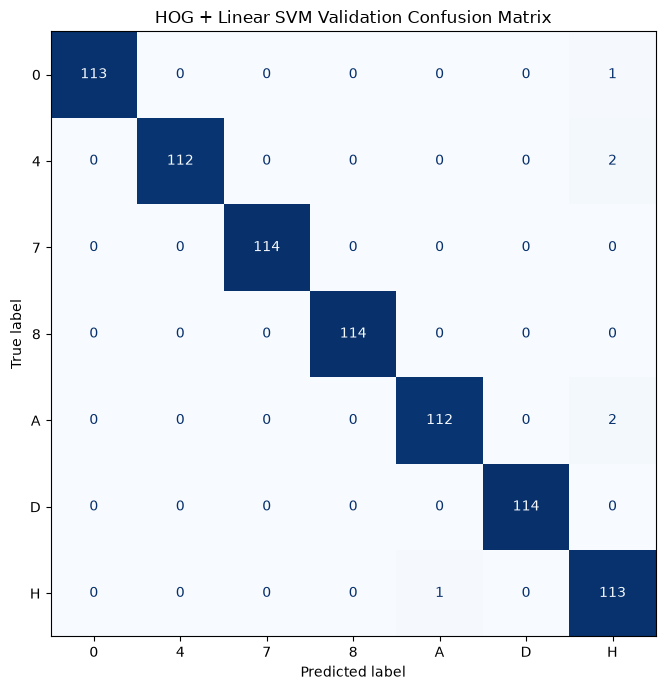

              precision    recall  f1-score   support

           0     1.0000    0.9912    0.9956       114
           4     1.0000    0.9825    0.9912       114
           7     1.0000    1.0000    1.0000       114
           8     1.0000    1.0000    1.0000       114
           A     0.9912    0.9825    0.9868       114
           D     1.0000    1.0000    1.0000       114
           H     0.9576    0.9912    0.9741       114

    accuracy                         0.9925       798
   macro avg     0.9927    0.9925    0.9925       798
weighted avg     0.9927    0.9925    0.9925       798



In [19]:

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)
import matplotlib.pyplot as plt
import numpy as np
import math

# Best candidate model
best_hog_model = hog_models["linear"]

# Validation predictions
y_val_pred_hog = best_hog_model.predict(X_val_hog)

class_names = ["0", "4", "7", "8", "A", "D", "H"]

# Confusion matrix
cm_hog = confusion_matrix(
    y_val,
    y_val_pred_hog,
    labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_hog,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("HOG + Linear SVM Validation Confusion Matrix")
plt.tight_layout()

plt.savefig(
    output_dir / "hog_linear_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(classification_report(
    y_val,
    y_val_pred_hog,
    labels=class_names,
    digits=4,
    zero_division=0
))


HOG + Linear SVM errors: 6


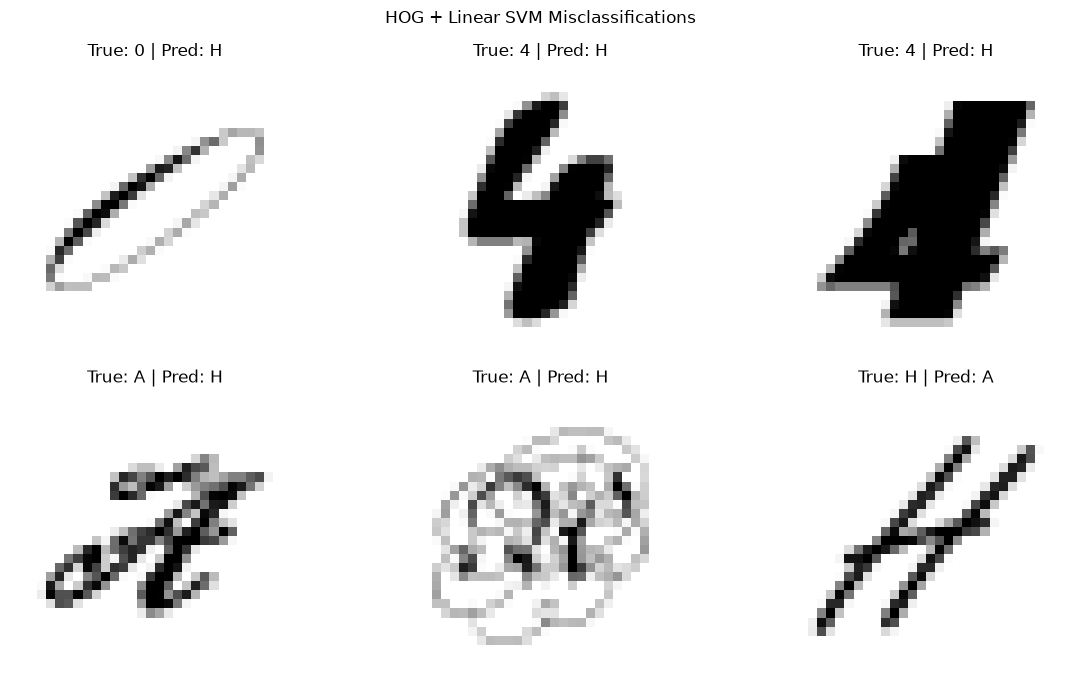

In [20]:

wrong_hog = np.where(y_val != y_val_pred_hog)[0]

n_errors = len(wrong_hog)
print("HOG + Linear SVM errors:", n_errors)

if n_errors > 0:
    ncols = 3
    nrows = math.ceil(n_errors / ncols)

    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(12, 3.5 * nrows),
        squeeze=False
    )

    for i, ax in enumerate(axes.flat):

        if i < n_errors:
            idx = wrong_hog[i]

            image = X_val[idx].reshape(32, 32)

            ax.imshow(image, cmap="gray",
                      vmin=0, vmax=1)

            ax.set_title(
                f"True: {y_val[idx]} | "
                f"Pred: {y_val_pred_hog[idx]}"
            )

        ax.axis("off")

    plt.suptitle("HOG + Linear SVM Misclassifications")
    plt.tight_layout()

    plt.savefig(
        output_dir / "hog_linear_misclassified.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


## 4. Image preprocessing study

Compare original resizing, crop + stretch, and crop + pad using identical training/validation samples.

In [21]:

def preprocess_compare(path, method="original"):

    image = cv2.imread(
        str(resolve_dataset_path(path)),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise FileNotFoundError(path)

    if method in ["crop_stretch", "crop_pad"]:

        # Detect dark foreground against white background
        mask = image < 245

        ys, xs = np.where(mask)

        if len(xs) > 0:

            x1, x2 = xs.min(), xs.max() + 1
            y1, y2 = ys.min(), ys.max() + 1

            image = image[y1:y2, x1:x2]

        if method == "crop_pad":

            h, w = image.shape

            # Add a 20% total margin
            side = int(np.ceil(max(h, w) * 1.20))

            top = (side - h) // 2
            bottom = side - h - top

            left = (side - w) // 2
            right = side - w - left

            image = cv2.copyMakeBorder(
                image,
                top, bottom,
                left, right,
                borderType=cv2.BORDER_CONSTANT,
                value=255
            )

    image = cv2.resize(
        image,
        (32, 32),
        interpolation=cv2.INTER_AREA
    )

    return image.astype(np.float32) / 255.0


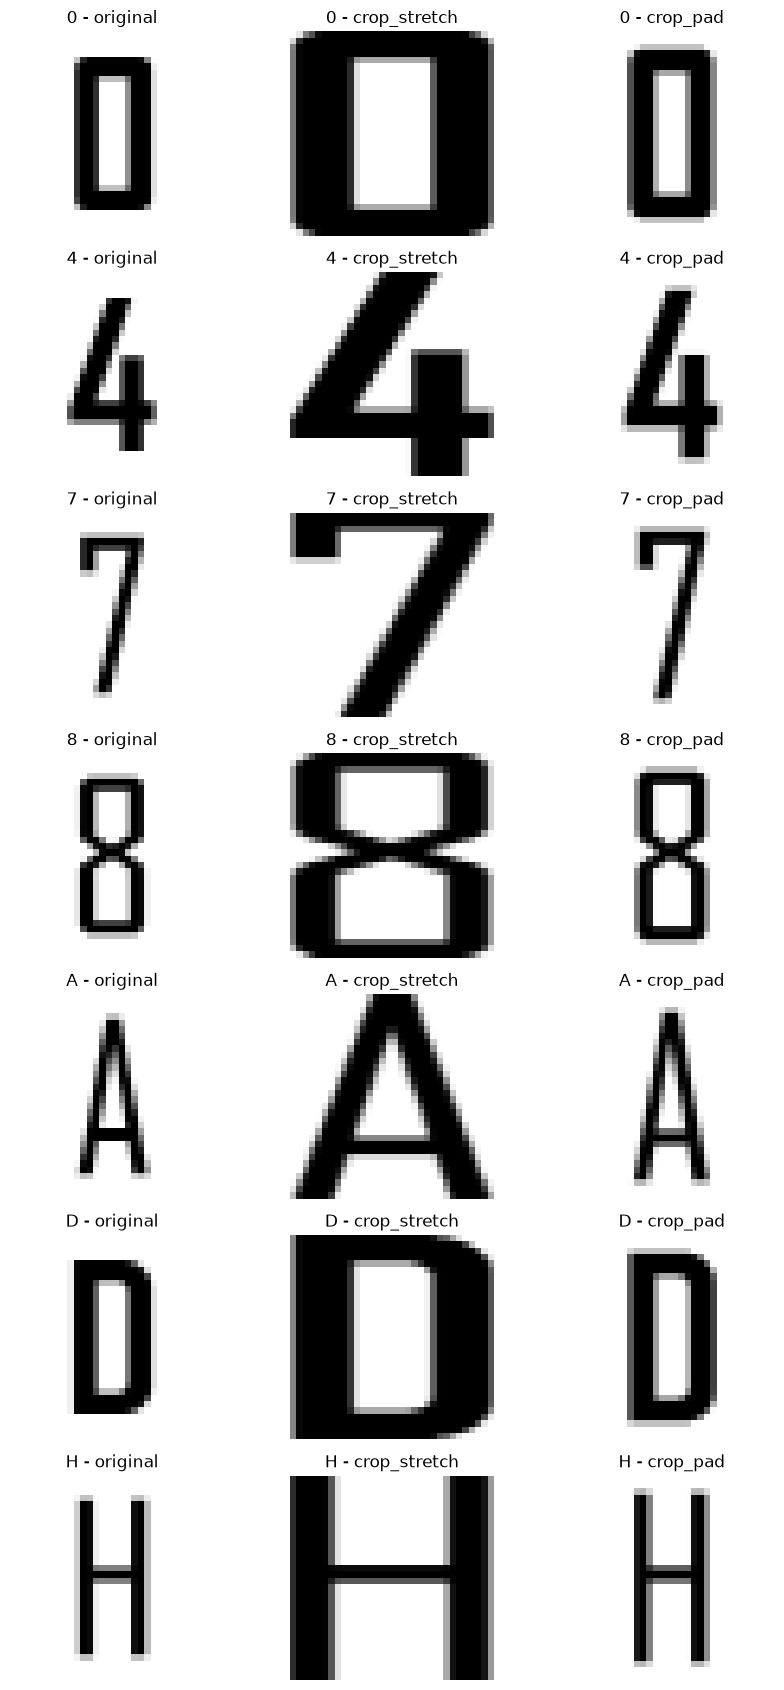

In [22]:

methods = [
    "original",
    "crop_stretch",
    "crop_pad"
]

fig, axes = plt.subplots(
    7, 3,
    figsize=(9, 17)
)

for row, label in enumerate(class_names):

    record = next(
        r for r in dataset_records
        if r["label"] == label and r["split"] == "train"
    )

    for col, method in enumerate(methods):

        image = preprocess_compare(
            record["path"],
            method
        )

        axes[row, col].imshow(
            image,
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[row, col].set_title(
            f"{label} - {method}"
        )

        axes[row, col].axis("off")

plt.tight_layout()

plt.savefig(
    output_dir / "preprocessing_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [23]:

import numpy as np
import time

def build_preprocessed_dataset(records, split_name, method):

    X = []
    y = []

    for record in records:

        if record["split"] != split_name:
            continue

        image = preprocess_compare(
            record["path"],
            method=method
        )

        X.append(image.flatten())
        y.append(record["label"])

    return (
        np.array(X, dtype=np.float32),
        np.array(y)
    )


# Store HOG features for each method
preprocessing_datasets = {}

methods = [
    "original",
    "crop_stretch",
    "crop_pad"
]

for method in methods:

    print(f"\nProcessing: {method}")

    X_tr, y_tr = build_preprocessed_dataset(
        dataset_records, "train", method
    )

    X_va, y_va = build_preprocessed_dataset(
        dataset_records, "val", method
    )

    # Ensure that labels and sample ordering match
    assert np.array_equal(y_tr, y_train)
    assert np.array_equal(y_va, y_val)

    X_tr_hog = extract_hog_features(X_tr)
    X_va_hog = extract_hog_features(X_va)

    preprocessing_datasets[method] = (
        X_tr_hog,
        X_va_hog
    )

    print("Training:", X_tr_hog.shape)
    print("Validation:", X_va_hog.shape)

print("\nAll preprocessing datasets prepared!")



Processing: original
Training: (4536, 324)
Validation: (798, 324)

Processing: crop_stretch
Training: (4536, 324)
Validation: (798, 324)

Processing: crop_pad
Training: (4536, 324)
Validation: (798, 324)

All preprocessing datasets prepared!


In [24]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
import time

preprocessing_results = []
preprocessing_models = {}

for method in methods:

    X_tr_hog, X_va_hog = preprocessing_datasets[method]

    model = SVC(
        kernel="linear",
        C=1.0
    )

    start = time.perf_counter()

    model.fit(X_tr_hog, y_train)

    training_time = time.perf_counter() - start

    predictions = model.predict(X_va_hog)

    accuracy = accuracy_score(
        y_val, predictions
    )

    macro_f1 = f1_score(
        y_val,
        predictions,
        average="macro"
    )

    errors = int(np.sum(y_val != predictions))

    preprocessing_models[method] = model

    preprocessing_results.append({
        "Method": method,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Errors": errors,
        "Training Time": training_time
    })

    print("-" * 50)
    print(f"Method: {method}")
    print(f"Validation Accuracy: {accuracy * 100:.2f}%")
    print(f"Macro F1-score: {macro_f1:.4f}")
    print(f"Incorrect predictions: {errors}")
    print(f"SVM training time: {training_time:.3f} s")


--------------------------------------------------
Method: original
Validation Accuracy: 99.25%
Macro F1-score: 0.9925
Incorrect predictions: 6
SVM training time: 0.132 s
--------------------------------------------------
Method: crop_stretch
Validation Accuracy: 99.75%
Macro F1-score: 0.9975
Incorrect predictions: 2
SVM training time: 0.114 s
--------------------------------------------------
Method: crop_pad
Validation Accuracy: 99.12%
Macro F1-score: 0.9912
Incorrect predictions: 7
SVM training time: 0.117 s


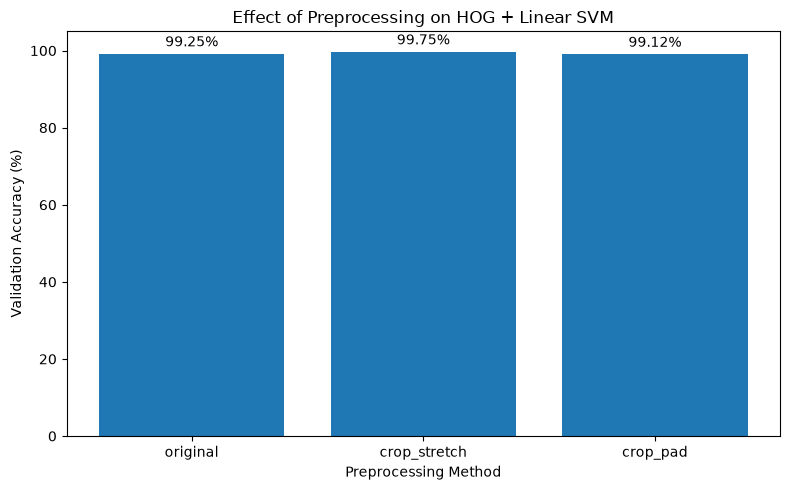

In [25]:

import matplotlib.pyplot as plt

names = [
    result["Method"]
    for result in preprocessing_results
]

accuracies = [
    result["Accuracy"] * 100
    for result in preprocessing_results
]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(names, accuracies)

ax.set_ylabel("Validation Accuracy (%)")
ax.set_xlabel("Preprocessing Method")
ax.set_title(
    "Effect of Preprocessing on HOG + Linear SVM"
)

ax.set_ylim(0, 105)

for bar, accuracy in zip(bars, accuracies):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    output_dir / "svm_preprocessing_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 5. Linear SVM hyperparameter selection

Select regularization parameter C on the validation set only.

In [26]:

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import time

# Use the best preprocessing candidate
X_tr_hog, X_va_hog = preprocessing_datasets["crop_stretch"]

# Candidate C values
C_values = [0.01, 0.1, 1.0, 10.0]

# Store results and trained models
tuning_results = []
tuning_models = {}

for C in C_values:

    model = SVC(
        kernel="linear",
        C=C
    )

    start = time.perf_counter()

    model.fit(X_tr_hog, y_train)

    training_time = time.perf_counter() - start

    predictions = model.predict(X_va_hog)

    accuracy = accuracy_score(
        y_val, predictions
    )

    macro_f1 = f1_score(
        y_val,
        predictions,
        average="macro"
    )

    errors = int(np.sum(y_val != predictions))

    tuning_models[C] = model

    tuning_results.append({
        "C": C,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Errors": errors,
        "Training Time": training_time
    })

    print("-" * 45)
    print(f"C = {C}")
    print(f"Accuracy: {accuracy * 100:.2f}%")
    print(f"Macro F1: {macro_f1:.4f}")
    print(f"Incorrect predictions: {errors}")
    print(f"Training time: {training_time:.3f} s")


---------------------------------------------
C = 0.01
Accuracy: 97.12%
Macro F1: 0.9711
Incorrect predictions: 23
Training time: 0.341 s
---------------------------------------------
C = 0.1
Accuracy: 99.00%
Macro F1: 0.9900
Incorrect predictions: 8
Training time: 0.132 s
---------------------------------------------
C = 1.0
Accuracy: 99.75%
Macro F1: 0.9975
Incorrect predictions: 2
Training time: 0.101 s
---------------------------------------------
C = 10.0
Accuracy: 99.87%
Macro F1: 0.9987
Incorrect predictions: 1
Training time: 0.098 s


In [27]:

# Select highest validation accuracy
# If tied, prefer the smaller C value

best_result = sorted(
    tuning_results,
    key=lambda r: (-r["Accuracy"], r["C"])
)[0]

best_C = best_result["C"]
best_model = tuning_models[best_C]

print("Best validation configuration")
print("=" * 45)

print("Preprocessing: crop_stretch")
print("Features: HOG")
print("Kernel: linear")
print("Best C:", best_C)

print(
    f"Best Validation Accuracy: "
    f"{best_result['Accuracy'] * 100:.2f}%"
)

print(
    f"Macro F1-score: "
    f"{best_result['Macro F1']:.4f}"
)

print(
    "Incorrect predictions:",
    best_result["Errors"]
)


Best validation configuration
Preprocessing: crop_stretch
Features: HOG
Kernel: linear
Best C: 10.0
Best Validation Accuracy: 99.87%
Macro F1-score: 0.9987
Incorrect predictions: 1


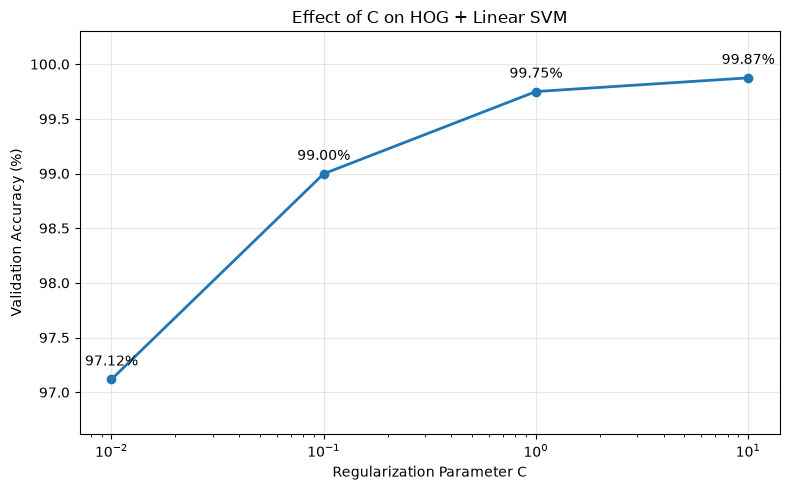

In [28]:

import matplotlib.pyplot as plt

C_list = [r["C"] for r in tuning_results]

accuracy_list = [
    r["Accuracy"] * 100
    for r in tuning_results
]

plt.figure(figsize=(8, 5))

plt.plot(
    C_list,
    accuracy_list,
    marker="o",
    linewidth=2
)

plt.xscale("log")

plt.xlabel("Regularization Parameter C")
plt.ylabel("Validation Accuracy (%)")
plt.title("Effect of C on HOG + Linear SVM")

plt.grid(True, alpha=0.3)

for C, acc in zip(C_list, accuracy_list):

    plt.annotate(
        f"{acc:.2f}%",
        (C, acc),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center"
    )

plt.ylim(
    min(accuracy_list) - 0.5,
    min(100.3, max(accuracy_list) + 0.5)
)

plt.tight_layout()

plt.savefig(
    output_dir / "svm_C_tuning.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 6. Final model fitting on development data

Retrain the selected HOG + Linear SVM on train + validation (5,334 images).

In [29]:

import numpy as np

# Retrieve the selected preprocessing features
X_train_final, X_val_final = preprocessing_datasets[
    "crop_stretch"
]

# Combine training and validation data
X_dev = np.concatenate(
    [X_train_final, X_val_final],
    axis=0
)

y_dev = np.concatenate(
    [y_train, y_val],
    axis=0
)

print("Final training data:", X_dev.shape)
print("Final training labels:", y_dev.shape)

assert X_dev.shape == (5334, 324)
assert len(y_dev) == 5334

print("Final training dataset is ready!")


Final training data: (5334, 324)
Final training labels: (5334,)
Final training dataset is ready!


In [30]:

from sklearn.svm import SVC
import time

final_svm = SVC(
    kernel="linear",
    C=10.0
)

start_time = time.perf_counter()

final_svm.fit(X_dev, y_dev)

final_training_time = (
    time.perf_counter() - start_time
)

print("Final SVM training completed!")
print("Training samples:", len(y_dev))
print("Number of classes:", len(final_svm.classes_))
print("Classes:", final_svm.classes_)
print(f"Training time: {final_training_time:.3f} s")


Final SVM training completed!
Training samples: 5334
Number of classes: 7
Classes: ['0' '4' '7' '8' 'A' 'D' 'H']
Training time: 0.129 s


## 7. Independent test evaluation

Evaluate only after hyperparameters are fixed; do not tune further using the test set.

In [31]:

# Load test images using the selected preprocessing
X_test, y_test = build_preprocessed_dataset(
    dataset_records,
    "test",
    "crop_stretch"
)

# Extract HOG features
X_test_hog = extract_hog_features(X_test)

print("Test images:", X_test.shape)
print("Test HOG features:", X_test_hog.shape)
print("Test labels:", y_test.shape)

assert X_test_hog.shape == (1778, 324)

print("Independent test dataset is ready!")


Test images: (1778, 1024)
Test HOG features: (1778, 324)
Test labels: (1778,)
Independent test dataset is ready!


In [32]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

# Measure SVM prediction time
start = time.perf_counter()

y_test_pred = final_svm.predict(X_test_hog)

test_inference_time = time.perf_counter() - start

# Calculate metrics
test_accuracy = accuracy_score(
    y_test,
    y_test_pred
)

test_macro_f1 = f1_score(
    y_test,
    y_test_pred,
    average="macro"
)

test_errors = int(np.sum(y_test != y_test_pred))

print("=" * 55)
print("FINAL SVM TEST RESULTS")
print("=" * 55)

print("Model: HOG + Linear SVM")
print("Preprocessing: Crop + Stretch")
print("C: 10.0")

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Macro F1-score: {test_macro_f1:.4f}")

print("Correct predictions:", len(y_test) - test_errors)
print("Incorrect predictions:", test_errors)

print(
    f"SVM inference time: "
    f"{test_inference_time / len(y_test) * 1000:.4f} ms/sample"
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        labels=class_names,
        digits=4,
        zero_division=0
    )
)


FINAL SVM TEST RESULTS
Model: HOG + Linear SVM
Preprocessing: Crop + Stretch
C: 10.0
Test Accuracy: 99.38%
Macro F1-score: 0.9938
Correct predictions: 1767
Incorrect predictions: 11
SVM inference time: 0.0186 ms/sample

Classification Report:
              precision    recall  f1-score   support

           0     0.9845    1.0000    0.9922       254
           4     0.9883    1.0000    0.9941       254
           7     1.0000    1.0000    1.0000       254
           8     0.9922    1.0000    0.9961       254
           A     0.9960    0.9685    0.9820       254
           D     1.0000    0.9882    0.9941       254
           H     0.9961    1.0000    0.9980       254

    accuracy                         0.9938      1778
   macro avg     0.9939    0.9938    0.9938      1778
weighted avg     0.9939    0.9938    0.9938      1778



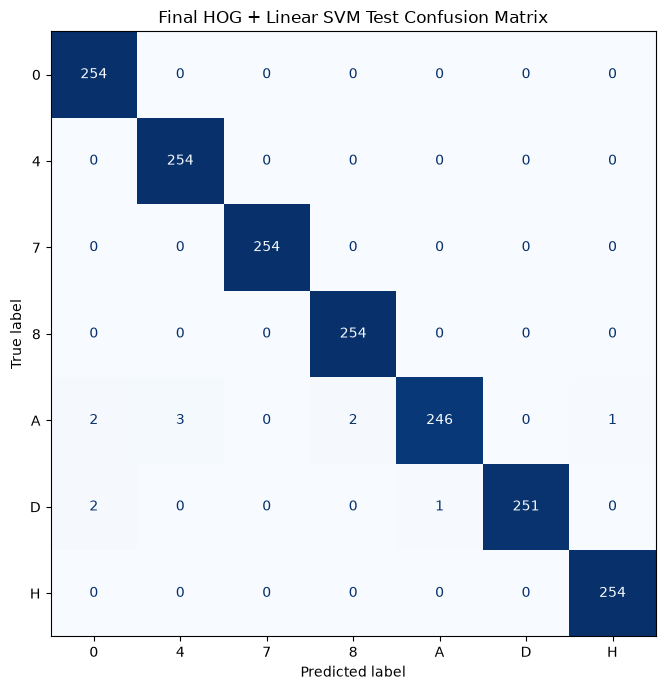

In [33]:

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
from pathlib import Path

output_dir = MODULE_ROOT / "results/task7"
output_dir.mkdir(parents=True, exist_ok=True)

cm_test = confusion_matrix(
    y_test,
    y_test_pred,
    labels=class_names
)

fig, ax = plt.subplots(figsize=(8, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Final HOG + Linear SVM Test Confusion Matrix")

plt.tight_layout()

plt.savefig(
    output_dir / "svm_final_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [34]:

import joblib

model_path = output_dir / "svm_final_model.joblib"

joblib.dump(
    {
        "model": final_svm,
        "preprocessing": "crop_stretch",
        "feature_extractor": "HOG",
        "image_size": 32,
        "C": 10.0,
        "class_names": list(final_svm.classes_)
    },
    model_path
)

print("Final SVM model saved to:", model_path)


Final SVM model saved to: results\task7\svm_final_model.joblib


## 8. Real chip inference — Pipeline A

Use the ten cleaned character crops exported by the original Task 6 pipeline (foreground white on black).

In [35]:

from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Folder containing cleaned Task 6 characters
chip_folder = MODULE_ROOT / "results/task6_characters_cleaned"

# Expected filenames
chip_paths = [
    chip_folder / f"character_{i:02d}.png"
    for i in range(1, 11)
]

print("Checking Task 6 character images:")

for path in chip_paths:
    print(path.name, "FOUND" if path.is_file() else "MISSING")

assert all(path.is_file() for path in chip_paths), (
    "Some character files are missing. "
    "Please check the folder path."
)

print("\nAll 10 character images are ready!")


Checking Task 6 character images:
character_01.png FOUND
character_02.png FOUND
character_03.png FOUND
character_04.png FOUND
character_05.png FOUND
character_06.png FOUND
character_07.png FOUND
character_08.png FOUND
character_09.png FOUND
character_10.png FOUND

All 10 character images are ready!


In [36]:

def preprocess_chip_character(image_path):

    # Read Task 6 binary character image
    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise FileNotFoundError(image_path)

    # Convert white character on black background
    # to black character on white background
    image = cv2.bitwise_not(image)

    # Locate the dark foreground
    mask = image < 245

    ys, xs = np.where(mask)

    if len(xs) == 0:
        raise ValueError(
            f"No character detected in {image_path}"
        )

    # Tight crop
    x1, x2 = xs.min(), xs.max() + 1
    y1, y2 = ys.min(), ys.max() + 1

    cropped = image[y1:y2, x1:x2]

    # Resize to 32x32, same as training
    resized = cv2.resize(
        cropped,
        (32, 32),
        interpolation=cv2.INTER_AREA
    )

    # Normalize to [0, 1]
    normalized = (
        resized.astype(np.float32) / 255.0
    )

    return normalized


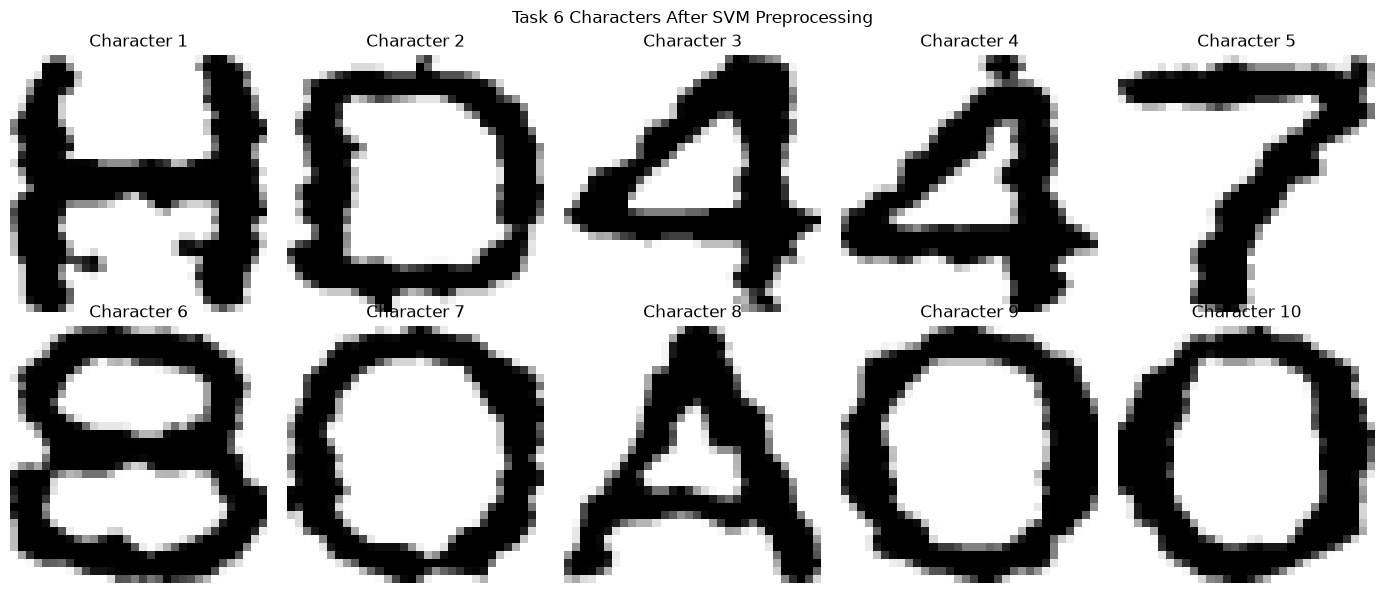

In [37]:

chip_processed = []

for path in chip_paths:

    processed = preprocess_chip_character(path)

    chip_processed.append(processed)

fig, axes = plt.subplots(
    2, 5,
    figsize=(14, 6)
)

for i, ax in enumerate(axes.flat):

    ax.imshow(
        chip_processed[i],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(f"Character {i+1}")
    ax.axis("off")

plt.suptitle("Task 6 Characters After SVM Preprocessing")

plt.tight_layout()
plt.show()


In [38]:

# Convert images to 1024-dimensional vectors
X_chip = np.array(
    [img.flatten() for img in chip_processed],
    dtype=np.float32
)

# Extract the same 324-dimensional HOG features
X_chip_hog = extract_hog_features(X_chip)

print("Chip image features:", X_chip.shape)
print("Chip HOG features:", X_chip_hog.shape)

# Predict with the final trained SVM
chip_predictions = final_svm.predict(X_chip_hog)

print("\nIndividual predictions:")

for i, prediction in enumerate(chip_predictions):
    print(f"Character {i+1}: {prediction}")

predicted_text = "".join(chip_predictions)

print("\nPredicted chip text:", predicted_text)


Chip image features: (10, 1024)
Chip HOG features: (10, 324)

Individual predictions:
Character 1: H
Character 2: D
Character 3: 4
Character 4: 4
Character 5: 7
Character 6: 8
Character 7: D
Character 8: A
Character 9: D
Character 10: 0

Predicted chip text: HD4478DAD0


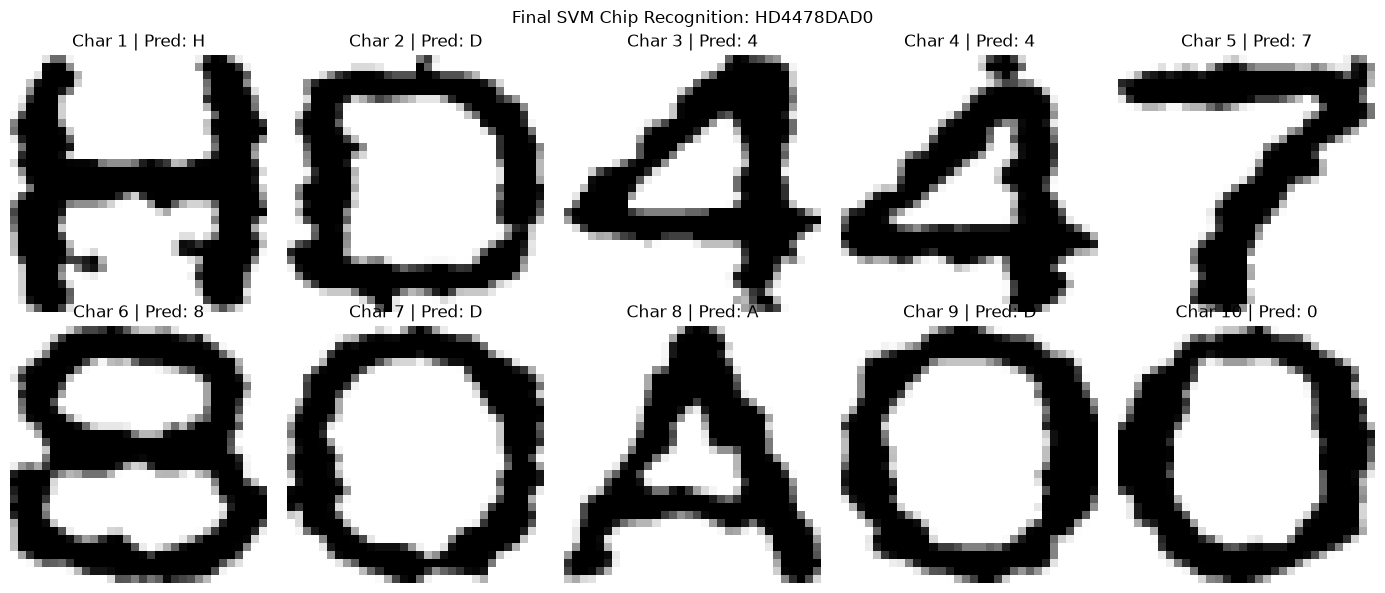

In [39]:

fig, axes = plt.subplots(
    2, 5,
    figsize=(14, 6)
)

for i, ax in enumerate(axes.flat):

    ax.imshow(
        chip_processed[i],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    ax.set_title(
        f"Char {i+1} | Pred: {chip_predictions[i]}"
    )

    ax.axis("off")

plt.suptitle(
    f"Final SVM Chip Recognition: {predicted_text}"
)

plt.tight_layout()

plt.savefig(
    output_dir / "svm_chip_recognition.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [40]:

reference_text = "HD44780A00"

correct_positions = sum(
    predicted == expected
    for predicted, expected in zip(
        chip_predictions,
        reference_text
    )
)

chip_accuracy = (
    correct_positions / len(reference_text)
)

print("Reference:", reference_text)
print("Predicted:", predicted_text)

print(
    f"Correct characters: "
    f"{correct_positions}/{len(reference_text)}"
)

print(
    f"Chip character accuracy: "
    f"{chip_accuracy * 100:.2f}%"
)


Reference: HD44780A00
Predicted: HD4478DAD0
Correct characters: 8/10
Chip character accuracy: 80.00%


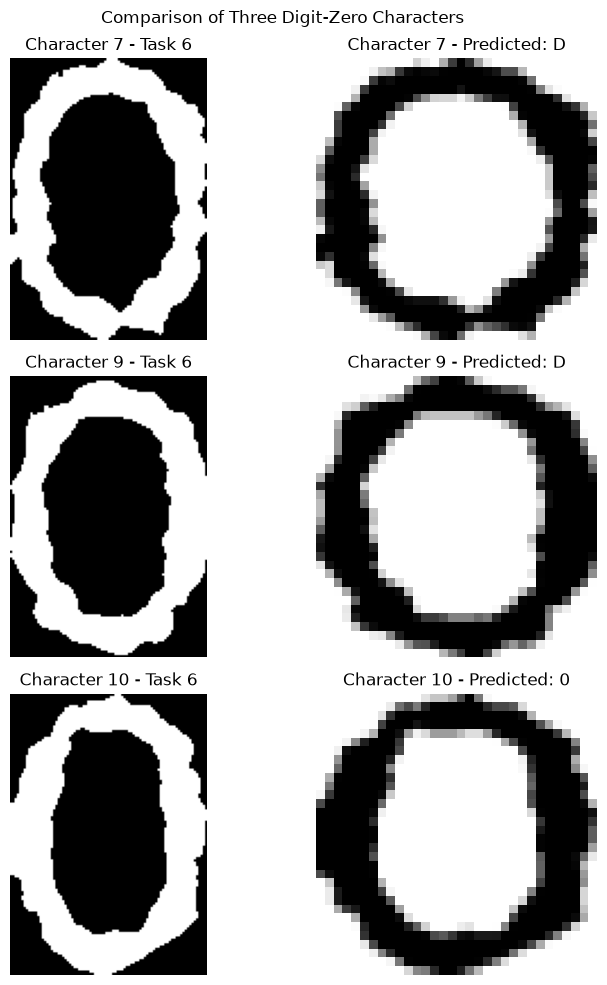

In [41]:

import cv2
import matplotlib.pyplot as plt

# Python indices for Character 7, 9 and 10
zero_indices = [6, 8, 9]

fig, axes = plt.subplots(
    3, 2,
    figsize=(8, 10)
)

for row, idx in enumerate(zero_indices):

    # Original cleaned Task 6 image
    original = cv2.imread(
        str(chip_paths[idx]),
        cv2.IMREAD_GRAYSCALE
    )

    # Processed image used by the SVM
    processed = chip_processed[idx]

    # Original segmentation
    axes[row, 0].imshow(
        original,
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axes[row, 0].set_title(
        f"Character {idx+1} - Task 6"
    )

    # SVM input
    axes[row, 1].imshow(
        processed,
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axes[row, 1].set_title(
        f"Character {idx+1} - "
        f"Predicted: {chip_predictions[idx]}"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.suptitle(
    "Comparison of Three Digit-Zero Characters"
)

plt.tight_layout()

plt.savefig(
    output_dir / "svm_zero_error_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 9. Real chip inference — Pipeline B

Use the ten crops exported from the teammate Task 6 connected-component pipeline with the **same** final SVM.

In [42]:

from pathlib import Path
import numpy as np

# Load teammate's segmented characters
teammate_folder = MODULE_ROOT / "results/task6_teammate_characters"

teammate_paths = [
    teammate_folder / f"character_{i:02d}.png"
    for i in range(1, 11)
]

assert all(p.is_file() for p in teammate_paths)

# Apply the same preprocessing as your SVM experiment
teammate_processed = [
    preprocess_chip_character(p)
    for p in teammate_paths
]

# Extract HOG features
X_teammate = np.array(
    [img.flatten() for img in teammate_processed],
    dtype=np.float32
)

X_teammate_hog = extract_hog_features(X_teammate)

# Use the SAME trained SVM
teammate_predictions = final_svm.predict(X_teammate_hog)

teammate_text = "".join(teammate_predictions)

reference_text = "HD44780A00"

correct = sum(
    pred == true
    for pred, true in zip(teammate_predictions, reference_text)
)

print("Reference:       ", reference_text)
print("Your Task 6:     ", predicted_text)
print("Teammate Task 6: ", teammate_text)

print(f"\nYour accuracy: 80.00%")
print(f"Teammate accuracy: {correct/10*100:.2f}%")


Reference:        HD44780A00
Your Task 6:      HD4478DAD0
Teammate Task 6:  HD44780ADD

Your accuracy: 80.00%
Teammate accuracy: 80.00%


## 10. Export comparison

Per-character predictions and correctness flags for both Task 6 pipelines.

In [43]:

import csv
from pathlib import Path

reference_text = "HD44780A00"

# Check sequence lengths
assert len(chip_predictions) == 10
assert len(teammate_predictions) == 10

comparison_rows = []

for i in range(10):
    true_label = reference_text[i]
    own_pred = str(chip_predictions[i])
    teammate_pred = str(teammate_predictions[i])

    comparison_rows.append({
        "Position": i + 1,
        "True Label": true_label,
        "Your Task 6": own_pred,
        "Teammate Task 6": teammate_pred,
        "Your Correct": own_pred == true_label,
        "Teammate Correct": teammate_pred == true_label
    })

# Save results
output_dir = MODULE_ROOT / "results/task7"
output_dir.mkdir(parents=True, exist_ok=True)

csv_path = output_dir / "task6_comparison.csv"

with open(csv_path, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=comparison_rows[0].keys()
    )
    writer.writeheader()
    writer.writerows(comparison_rows)

own_correct = sum(r["Your Correct"] for r in comparison_rows)
team_correct = sum(r["Teammate Correct"] for r in comparison_rows)

print("Reference:", reference_text)
print("Your prediction:", "".join(chip_predictions))
print("Teammate prediction:", "".join(teammate_predictions))

print(f"\nYour accuracy: {own_correct}/10 = {own_correct*10}%")
print(f"Teammate accuracy: {team_correct}/10 = {team_correct*10}%")

print("\nComparison saved to:", csv_path)


Reference: HD44780A00
Your prediction: HD4478DAD0
Teammate prediction: HD44780ADD

Your accuracy: 8/10 = 80%
Teammate accuracy: 8/10 = 80%

Comparison saved to: results\task7\task6_comparison.csv
